In [1]:
#Instalación de dependencias
!pip install -q mlflow
!pip install -q kagglehub[pandas-datasets]

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 638.2 kB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 2.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 35.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 33.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 51.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 16.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 7.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 6.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 9.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.7/148.7 kB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1

In [2]:
#Importación de librerías
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import kagglehub
from kagglehub import KaggleDatasetAdapter

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV
)

from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import mlflow
import mlflow.sklearn

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


In [3]:
#Carga del dataset desde Kaggle
file_path = "/creditcard.csv"

df = kagglehub.load_dataset(
    KaggleDatasetAdapter.PANDAS,
    "mlg-ulb/creditcardfraud",
    file_path
)

print("Dataset cargado correctamente.")
print(df.shape)

df.head()

Using Colab cache for faster access to the 'creditcardfraud' dataset.
Dataset cargado correctamente.
(284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [4]:
#Exploración inicial
print("Dimensiones:")
print(df.shape)

print("\nValores nulos:")
print(df.isnull().sum().sum())

print("\nTipos de datos:")
print(df.dtypes)

print("\nDistribución de clases:")
print(df["Class"].value_counts())

Dimensiones:
(284807, 31)

Valores nulos:
0

Tipos de datos:
Time      float64
V1        float64
V2        float64
V3        float64
V4        float64
V5        float64
V6        float64
V7        float64
V8        float64
V9        float64
V10       float64
V11       float64
V12       float64
V13       float64
V14       float64
V15       float64
V16       float64
V17       float64
V18       float64
V19       float64
V20       float64
V21       float64
V22       float64
V23       float64
V24       float64
V25       float64
V26       float64
V27       float64
V28       float64
Amount    float64
Class       int64
dtype: object

Distribución de clases:
Class
0    284315
1       492
Name: count, dtype: int64


In [5]:
#Estadísticas descriptivas
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.168375e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.416908e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.074095e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,9.604066e-16,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.487313e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.556467e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.213481e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.406331e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995


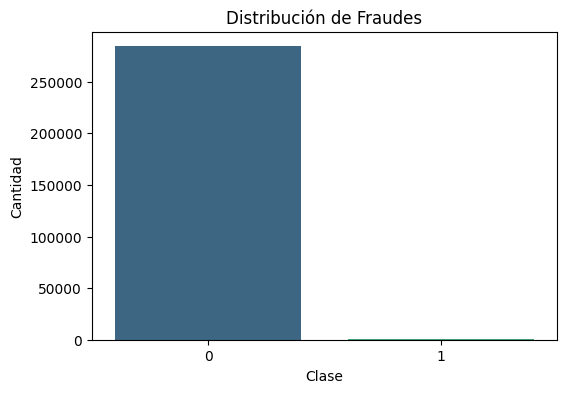

In [6]:
#Balance de clases
plt.figure(figsize=(6,4))

sns.countplot(
    data=df,
    x="Class",
    palette="viridis"
)

plt.title("Distribución de Fraudes")
plt.xlabel("Clase")
plt.ylabel("Cantidad")

plt.show()

In [7]:
#Porcentaje de fraude
fraudes = df["Class"].value_counts()[1]
normales = df["Class"].value_counts()[0]

print("Transacciones normales:", normales)
print("Fraudes:", fraudes)

print(
    "Porcentaje de fraude: {:.4f}%".format(
        (fraudes/len(df))*100
    )
)

Transacciones normales: 284315
Fraudes: 492
Porcentaje de fraude: 0.1727%


In [8]:
#Escalado de variables
df_limpio = df.copy()

scaler = StandardScaler()

df_limpio["Time"] = scaler.fit_transform(
    df_limpio[["Time"]]
)

df_limpio["Amount"] = scaler.fit_transform(
    df_limpio[["Amount"]]
)

df_limpio.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,-1.996583,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,0.244964,0
1,-1.996583,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,-0.342475,0
2,-1.996562,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,1.160686,0
3,-1.996562,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,0.140534,0
4,-1.996541,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,-0.073403,0


In [9]:
#Separación de variables
X = df_limpio.drop(
    columns=["Class"]
)

y = df_limpio["Class"]

print(X.shape)
print(y.shape)

(284807, 30)
(284807,)


In [10]:
#División Train-Test
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)

Entrenamiento: (227845, 30)
Prueba: (56962, 30)


In [11]:
#Configuración MLflow
mlflow.set_experiment(
    "Fraud_Detection_Project"
)

print("Experimento MLflow configurado.")

2026/10/19 02:18:04 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/19 02:18:04 INFO mlflow.store.db.utils: Updating database tables
2026/10/19 02:18:08 INFO mlflow.tracking.fluent: Experiment with name 'Fraud_Detection_Project' does not exist. Creating a new experiment.


Experimento MLflow configurado.


In [12]:
#Entrenamiento Regresión Logística
parametros_lr = {
    "C": [0.01, 0.1, 1, 10],
    "solver": ["liblinear"]
}

grid_lr = GridSearchCV(
    estimator=LogisticRegression(
        class_weight="balanced",
        random_state=42
    ),
    param_grid=parametros_lr,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

grid_lr.fit(
    X_train,
    y_train
)

print("Mejores parámetros:")
print(grid_lr.best_params_)

Mejores parámetros:
{'C': 0.01, 'solver': 'liblinear'}


In [13]:
#Evaluación Regresión Logística
modelo_lr = grid_lr.best_estimator_

y_pred_lr = modelo_lr.predict(X_test)

y_prob_lr = modelo_lr.predict_proba(X_test)[:,1]

acc_lr = accuracy_score(
    y_test,
    y_pred_lr
)

prec_lr = precision_score(
    y_test,
    y_pred_lr
)

rec_lr = recall_score(
    y_test,
    y_pred_lr
)

f1_lr = f1_score(
    y_test,
    y_pred_lr
)

auc_lr = roc_auc_score(
    y_test,
    y_prob_lr
)

print(classification_report(
    y_test,
    y_pred_lr
))

              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56864
           1       0.06      0.92      0.12        98

    accuracy                           0.98     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.98      0.99     56962



In [14]:
#Registro MLflow Regresión Logística
with mlflow.start_run(
    run_name="Logistic_Regression"
):

    mlflow.log_params(
        grid_lr.best_params_
    )

    mlflow.log_metric(
        "Accuracy",
        acc_lr
    )

    mlflow.log_metric(
        "Precision",
        prec_lr
    )

    mlflow.log_metric(
        "Recall",
        rec_lr
    )

    mlflow.log_metric(
        "F1",
        f1_lr
    )

    mlflow.log_metric(
        "ROC_AUC",
        auc_lr
    )

    mlflow.sklearn.log_model(
        modelo_lr,
        "LogisticRegression"
    )

print("Modelo LR registrado.")

2026/10/19 02:20:29 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Modelo LR registrado.


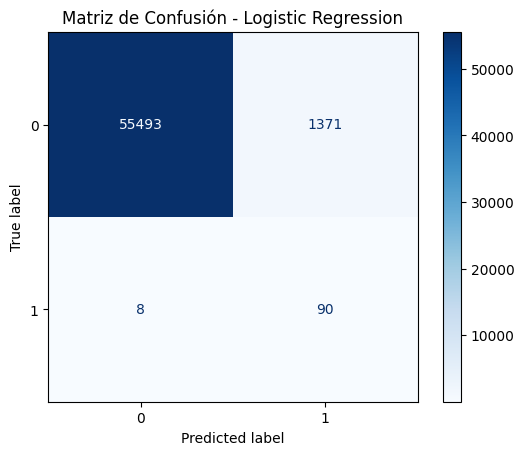

In [15]:
#Matriz de confusión LR
cm = confusion_matrix(
    y_test,
    y_pred_lr
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm
)

disp.plot(
    cmap="Blues"
)

plt.title(
    "Matriz de Confusión - Logistic Regression"
)

plt.show()

In [ ]:
#Entrenamiento Random Forest
# Definición de hiperparámetros para Grid Search

parametros_rf = {
    "n_estimators": [100, 200],
    "max_depth": [5, 10, None],
    "min_samples_split": [2, 5]
}

# Configuración del modelo Random Forest

grid_rf = GridSearchCV(
    estimator=RandomForestClassifier(
        random_state=42,
        class_weight="balanced"
    ),
    param_grid=parametros_rf,
    cv=5,
    scoring="f1",
    n_jobs=-1,
    verbose=1
)

# Entrenamiento del modelo

grid_rf.fit(
    X_train,
    y_train
)

# Mostrar mejores resultados

print("Mejores parámetros encontrados:")
print(grid_rf.best_params_)

print("\nMejor F1 obtenido en validación cruzada:")
print(grid_rf.best_score_)

# Guardar el mejor modelo

modelo_rf = grid_rf.best_estimator_

print("\nModelo seleccionado:")
print(modelo_rf)

Fitting 5 folds for each of 12 candidates, totalling 60 fits


In [ ]:
#Evaluación Random Forest
modelo_rf = grid_rf.best_estimator_

y_pred_rf = modelo_rf.predict(
    X_test
)

y_prob_rf = modelo_rf.predict_proba(
    X_test
)[:,1]

acc_rf = accuracy_score(
    y_test,
    y_pred_rf
)

prec_rf = precision_score(
    y_test,
    y_pred_rf
)

rec_rf = recall_score(
    y_test,
    y_pred_rf
)

f1_rf = f1_score(
    y_test,
    y_pred_rf
)

auc_rf = roc_auc_score(
    y_test,
    y_prob_rf
)

print(classification_report(
    y_test,
    y_pred_rf
))

In [ ]:
#Registro MLflow Random Forest
with mlflow.start_run(
    run_name="Random_Forest"
):

    mlflow.log_params(
        grid_rf.best_params_
    )

    mlflow.log_metric(
        "Accuracy",
        acc_rf
    )

    mlflow.log_metric(
        "Precision",
        prec_rf
    )

    mlflow.log_metric(
        "Recall",
        rec_rf
    )

    mlflow.log_metric(
        "F1",
        f1_rf
    )

    mlflow.log_metric(
        "ROC_AUC",
        auc_rf
    )

    mlflow.sklearn.log_model(
        modelo_rf,
        "RandomForest"
    )

print("Modelo RF registrado.")

In [ ]:
#Matriz de confusión RF
cm = confusion_matrix(
    y_test,
    y_pred_rf
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm
)

disp.plot(
    cmap="Greens"
)

plt.title(
    "Matriz de Confusión - Random Forest"
)

plt.show()

In [ ]:
#Comparación final de modelos
resultados = pd.DataFrame({

    "Modelo": [
        "Logistic Regression",
        "Random Forest"
    ],

    "Accuracy": [
        acc_lr,
        acc_rf
    ],

    "Precision": [
        prec_lr,
        prec_rf
    ],

    "Recall": [
        rec_lr,
        rec_rf
    ],

    "F1 Score": [
        f1_lr,
        f1_rf
    ],

    "ROC_AUC": [
        auc_lr,
        auc_rf
    ]
})

resultados

In [ ]:
#Gráfico comparativo
metricas = resultados.set_index(
    "Modelo"
)

metricas.plot(
    kind="bar",
    figsize=(12,6)
)

plt.title(
    "Comparación de Modelos"
)

plt.ylabel(
    "Valor Métrica"
)

plt.xticks(
    rotation=0
)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.5
)

plt.show()

In [ ]:
Selección del mejor modelo
mejor_modelo = resultados.loc[
    resultados["F1 Score"].idxmax()
]

print("Modelo ganador")
print("="*50)

print(
    mejor_modelo
*  "\n"
)

In [ ]:
#Conclusiones
print("""
CONCLUSIONES

1.*Se evaluaron dos algoritmos de clasificación:
   - Regresión Logística
   - Random Forest

2.*Se utilizó GridSearchCV con validación cruzada k=5.

3.*Todas las ejecuciones fueron registradas con MLflow.

4.*Debido al fuerte desbalance del dataset,
   las métricas más importantes fueron
   Recal, F1 Score y ROC-AUC.

5.*El modelo con mayor F1-Score se considera
   la mejor alternativa para el sistema
  de detección de fraudes.

6.*Los resultados permiten justificar
   la implementación de modelos de IA
   para apoyar la identificación temprana
   de transacciones sospechosas
""")